# Synthetic Image Detection: MobileNetV2 Transfer Learning

## Overview

This notebook applies transfer learning using MobileNetV2 to classify images as real or AI-generated.

The model will be evaluated on the CIFAKE dataset and compared with the CNN baseline developed in the previous notebook.

## 1. Imports and Dataset Setup

In [23]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report

## 2. Data Loading and Preprocessing

In [5]:
dataset_path = Path('../dataset/archive')

train_dir = dataset_path / 'train'
test_dir = dataset_path / 'test'

IMG_SIZE = (96,96)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(train_dir, validation_split = 0.2, subset = 'training',
                                                    seed = SEED, image_size = IMG_SIZE, batch_size = BATCH_SIZE,
                                                    label_mode = 'binary')
val_ds = keras.utils.image_dataset_from_directory(train_dir, validation_split = 0.2, subset = 'validation',
                                                    seed = SEED, image_size = IMG_SIZE, batch_size = BATCH_SIZE,
                                                    label_mode = 'binary')
test_ds = keras.utils.image_dataset_from_directory(test_dir, image_size = IMG_SIZE, batch_size = BATCH_SIZE,
                                                    label_mode = 'binary', shuffle = False)

Found 100000 files belonging to 2 classes.
Using 80000 files for training.
Found 100000 files belonging to 2 classes.
Using 20000 files for validation.
Found 20000 files belonging to 2 classes.


In [6]:
print(f'Classes: {train_ds.class_names}')
print(f'Training batches: {tf.data.experimental.cardinality(train_ds).numpy()}')
print(f'Validation batches: {tf.data.experimental.cardinality(val_ds).numpy()}')
print(f'Test batches: {tf.data.experimental.cardinality(test_ds).numpy()}')

Classes: ['FAKE', 'REAL']
Training batches: 2500
Validation batches: 625
Test batches: 625


## 3. Loading the Pretrained MobileNetV2 Model

In [7]:
base_model = keras.applications.MobileNetV2(input_shape=(96,96,3), include_top = False, weights = 'imagenet')
base_model.trainable = False

print(f'Total layers: {len(base_model.layers)}')
print(f'Trainable layers: {sum(layer.trainable for layer in base_model.layers)}')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step
Total layers: 154
Trainable layers: 0


## 4. Building the Classification Model

In [9]:
inputs = keras.Input(shape=(96,96,3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(1, activation='sigmoid')(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide_1 (TrueDivide)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract_1 (Subtract)                │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_96 (Functional)     │ (None, 3, 3, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Compiling and Training the Model

In [10]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10


C:\Users\Onabanjo Daniel\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2500/2500 ━━━━━━━━━━━━━━━━━━━━ 527s 207ms/step - accuracy: 0.8641 - loss: 0.3120 - val_accuracy: 0.8798 - val_loss: 0.2824
Epoch 2/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 933s 373ms/step - accuracy: 0.8890 - loss: 0.2660 - val_accuracy: 0.8929 - val_loss: 0.2583
Epoch 3/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 366s 147ms/step - accuracy: 0.8915 - loss: 0.2612 - val_accuracy: 0.8928 - val_loss: 0.2576
Epoch 4/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 327s 131ms/step - accuracy: 0.8933 - loss: 0.2585 - val_accuracy: 0.8907 - val_loss: 0.2625
Epoch 5/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 335s 134ms/step - accuracy: 0.8934 - loss: 0.2580 - val_accuracy: 0.8895 - val_loss: 0.2651
Epoch 6/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 326s 130ms/step - accuracy: 0.8925 - loss: 0.2580 - val_accuracy: 0.8871 - val_loss: 0.2709
Epoch 7/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 315s 126ms/step - accuracy: 0.8934 - loss: 0.2573 - val_accuracy: 0.8903 - val_loss: 0.2638
Epoch 8/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 315s 126ms/step - accuracy: 0.8

In [15]:
model.save('../models/mobilenetv2_feature_extraction.keras')

## 6. Training Performance

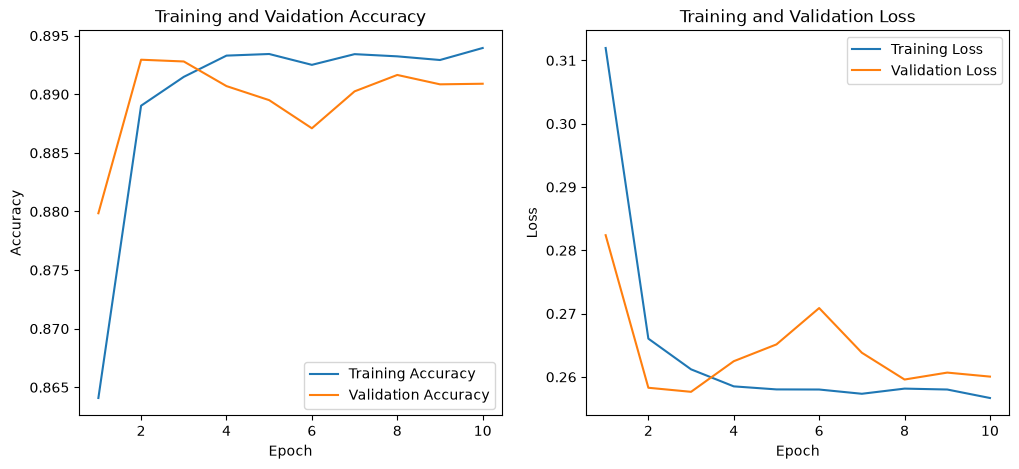

In [16]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc)+1)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Vaidation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

## 7. Test Set Evaluation

In [13]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test loss: {test_loss:.4f}')

625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 110ms/step - accuracy: 0.8924 - loss: 0.2626
Test accuracy: 0.8924
Test loss: 0.2626


In [14]:
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])
y_prob = model.predict(test_ds)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print(classification_report(y_true, y_pred, target_names = ['FAKE', 'REAL']))

625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 104ms/step
              precision    recall  f1-score   support

        FAKE       0.89      0.89      0.89     10000
        REAL       0.89      0.89      0.89     10000

    accuracy                           0.89     20000
   macro avg       0.89      0.89      0.89     20000
weighted avg       0.89      0.89      0.89     20000



## 8. Fine-Tuning MobileNetV2

In [17]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(f'Total layers: {len(base_model.layers)}')
print(f'Trainable layers: {sum(layer.trainable for layer in base_model.layers)}')

Total layers: 154
Trainable layers: 19


In [18]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])
fine_tune_history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10


C:\Users\Onabanjo Daniel\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2500/2500 ━━━━━━━━━━━━━━━━━━━━ 664s 262ms/step - accuracy: 0.9233 - loss: 0.1940 - val_accuracy: 0.9395 - val_loss: 0.1563
Epoch 2/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 573s 229ms/step - accuracy: 0.9540 - loss: 0.1202 - val_accuracy: 0.9468 - val_loss: 0.1376
Epoch 3/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 527s 211ms/step - accuracy: 0.9693 - loss: 0.0846 - val_accuracy: 0.9523 - val_loss: 0.1259
Epoch 4/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 509s 204ms/step - accuracy: 0.9803 - loss: 0.0593 - val_accuracy: 0.9530 - val_loss: 0.1266
Epoch 5/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 516s 207ms/step - accuracy: 0.9877 - loss: 0.0415 - val_accuracy: 0.9562 - val_loss: 0.1220
Epoch 6/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 511s 204ms/step - accuracy: 0.9930 - loss: 0.0287 - val_accuracy: 0.9567 - val_loss: 0.1237
Epoch 7/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 614s 245ms/step - accuracy: 0.9961 - loss: 0.0194 - val_accuracy: 0.9580 - val_loss: 0.1276
Epoch 8/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 617s 247ms/step - accuracy: 0.9

In [19]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test loss: {test_loss:.4f}')

625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 102ms/step - accuracy: 0.9596 - loss: 0.1402
Test accuracy: 0.9596
Test loss: 0.1402


In [20]:
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])
y_prob = model.predict(test_ds)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print(classification_report(y_true, y_pred, target_names = ['FAKE', 'REAL']))

625/625 ━━━━━━━━━━━━━━━━━━━━ 77s 121ms/step
              precision    recall  f1-score   support

        FAKE       0.96      0.96      0.96     10000
        REAL       0.96      0.96      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000



In [21]:
model.save('../models/mobilenetv2_fine_tuned.keras')

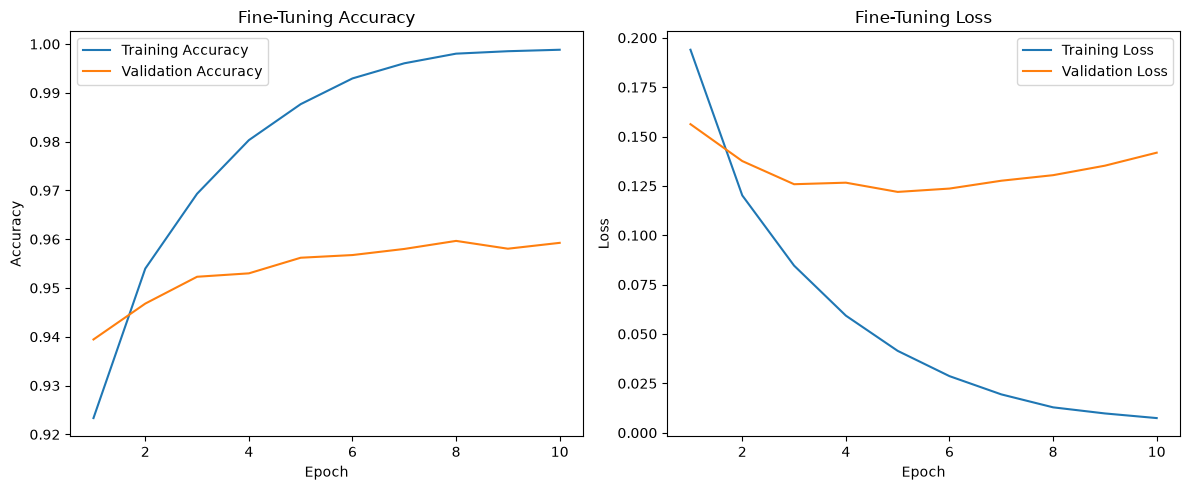

In [22]:
acc = fine_tune_history.history['accuracy']
val_acc = fine_tune_history.history['val_accuracy']

loss = fine_tune_history.history['loss']
val_loss = fine_tune_history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Fine-Tuning Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Fine-Tuning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 9. Model Comparison

In [24]:
comparison = pd.DataFrame({
    'Model': ['CNN Baseline', 'MobileNetV2 (Feature Extraction)', 'MobileNetV2 (Fine-Tuned)'],
    'Test Accuracy': [0.92945, 0.8924, 0.9596],
    'Test Loss': [0.2104, 0.2626, 0.1402],
    'Macro F1-Score': [0.93,0.89,0.96]})

comparison

,Model,Test Accuracy,Test Loss,Macro F1-Score
0,CNN Baseline,0.92945,0.2104,0.93
1,MobileNetV2 (Feature Extraction),0.89240,0.2626,0.89
2,MobileNetV2 (Fine-Tuned),0.95960,0.1402,0.96


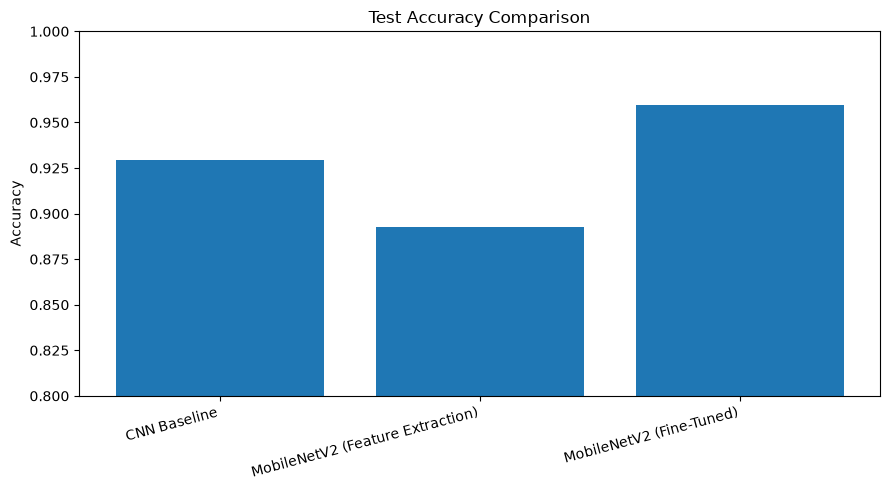

In [25]:
plt.figure(figsize=(9, 5))

plt.bar(comparison['Model'], comparison['Test Accuracy'])

plt.title('Test Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.80, 1.00)
plt.xticks(rotation=15, ha='right')

plt.tight_layout()
plt.show()

## 10. Results and Discussion

Three approaches were evaluated on the CIFAKE test set: a CNN trained from scratch, MobileNetV2 using feature extraction, and MobileNetV2 after fine-tuning.

The CNN baseline achieved **92.94% test accuracy**. MobileNetV2 using frozen pretrained features achieved **89.24%**, performing below the baseline.

After fine-tuning the deeper layers of MobileNetV2, test accuracy improved to **95.96%**, making it the best-performing model in this experiment.

The fine-tuned model also achieved a test loss of 0.1402 and a macro-average F1-score of 96%. Precision and recall were both approximately 96% for the FAKE and REAL classes.

### Effect of Fine-Tuning

Fine-tuning improved MobileNetV2 test accuracy by approximately 6.72 percentage points compared with feature extraction. This demonstrates the benefit of adapting pretrained features to the target classification task rather than relying entirely on the original ImageNet representations.

The training curves also showed signs of overfitting during fine-tuning. Training accuracy reached 99.88%, while validation accuracy remained around 96%. Validation loss reached its minimum at epoch 5 before increasing, suggesting that further training was no longer improving generalisation.

### Conclusion

Fine-tuned MobileNetV2 outperformed the CNN baseline by approximately 3.02 percentage points in test accuracy. For this experiment, it provided the strongest classification performance among the three approaches.

These results are specific to the CIFAKE dataset and do not establish that the model can reliably identify AI-generated images from arbitrary sources or image generators.

## 11. Limitations

- **Dataset dependency:** Evaluation was performed exclusively on CIFAKE. Performance on images from other datasets, generators, or real-world sources has not been established.
- **Image resolution:** Images were resized to 96×96 for MobileNetV2, potentially removing fine-grained details relevant to synthetic image detection.
- **Overfitting:** The fine-tuned model achieved 99.88% training accuracy, compared with 95.92% validation accuracy, indicating some overfitting.
- **Generalisation:** The experiment does not establish robustness against newer image-generation techniques, image compression, or post-processing.
- **Model efficiency:** Although MobileNetV2 is designed for efficient deployment, inference speed and resource requirements were not benchmarked in this experiment.